In [ ]:
import pandas as pd
import os
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
feat = pd.read_csv("/content/drive/MyDrive/BTT_Amazon1A_Studio/feat.csv")

In [ ]:
feat.head()

,Customer ID,SnapshotMonth,month_orders,month_revenue,month_quantity,month_diff_items,month_last_order,month_cancellations,cancellation_rate,churn,snapshot_end,last_order,first_order,total_orders,tenure_days,recency_days,frequency,orders_30d,orders_60d,orders_90d
0,12346,2009-12,2.0,113.50,26.0,2.0,2009-12-18 10:55:00,0.0,0.000000,0,2009-12-31,2009-12-18 10:55:00,2009-12-14 08:34:00,5.0,16.0,12.0,5.0,5.0,5.0,5.0
1,14606,2009-12,11.0,1401.59,527.0,210.0,2009-12-21 14:33:00,12.0,1.090909,0,2009-12-31,2009-12-21 14:33:00,2009-12-03 12:40:00,8.0,27.0,9.0,8.0,8.0,8.0,8.0
2,14605,2009-12,1.0,208.60,133.0,31.0,2009-12-08 13:59:00,0.0,0.000000,1,2009-12-31,2009-12-08 14:01:00,2009-12-08 13:59:00,2.0,22.0,22.0,2.0,2.0,2.0,2.0
3,14593,2009-12,1.0,391.68,157.0,65.0,2009-12-09 12:57:00,2.0,2.000000,0,2009-12-31,2009-12-09 12:57:00,2009-12-09 12:57:00,1.0,21.0,21.0,1.0,1.0,1.0,1.0
4,14590,2009-12,3.0,349.66,108.0,38.0,2009-12-16 11:26:00,0.0,0.000000,0,2009-12-31,2009-12-16 11:26:00,2009-12-07 14:10:00,3.0,23.0,14.0,3.0,3.0,3.0,3.0


In [ ]:
feat.columns

Index(['Customer ID', 'SnapshotMonth', 'month_orders', 'month_revenue',
       'month_quantity', 'month_diff_items', 'month_last_order',
       'month_cancellations', 'cancellation_rate', 'churn', 'snapshot_end',
       'last_order', 'first_order', 'total_orders', 'tenure_days',
       'recency_days', 'frequency', 'orders_30d', 'orders_60d', 'orders_90d'],
      dtype='object')

In [ ]:
cluster_cols = ['frequency', 'tenure_days', 'total_orders', 'cancellation_rate'] # Features we will use for clustering

X = feat[cluster_cols].copy()

In [ ]:
X.isna().sum()

,0
frequency,387
tenure_days,387
total_orders,387
cancellation_rate,5064


In [ ]:
X = X.fillna(X.median())

In [ ]:
X.isna().sum()

,0
frequency,0
tenure_days,0
total_orders,0
cancellation_rate,0


In [ ]:
from sklearn.preprocessing import StandardScaler


In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20) # Initialize kmeans hyperparameters

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



# Only features that are nonnegative and strongly right-skewed
cluster_cols = ['frequency', 'tenure_days', 'total_orders', 'cancellation_rate'] # Features we will use for clustering

# Keep all rows/customers
X_transformed = feat[cluster_cols].copy()
for col in cluster_cols:
    X_transformed[col] = np.log1p(X_transformed[col])

X_scaled2 = StandardScaler().fit_transform(X_transformed)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
feat["cluster2"] = kmeans.fit_predict(X_scaled2)

In [ ]:
# Confirm the new column exists and inspect assignments
feat[["Customer ID", "cluste2r"]].head()
# Number of customer-month rows assigned to each cluster
feat["cluster2"].value_counts().sort_index()
# Check whether every row received a cluster
feat["cluster2"].isnull().sum()

np.int64(0)

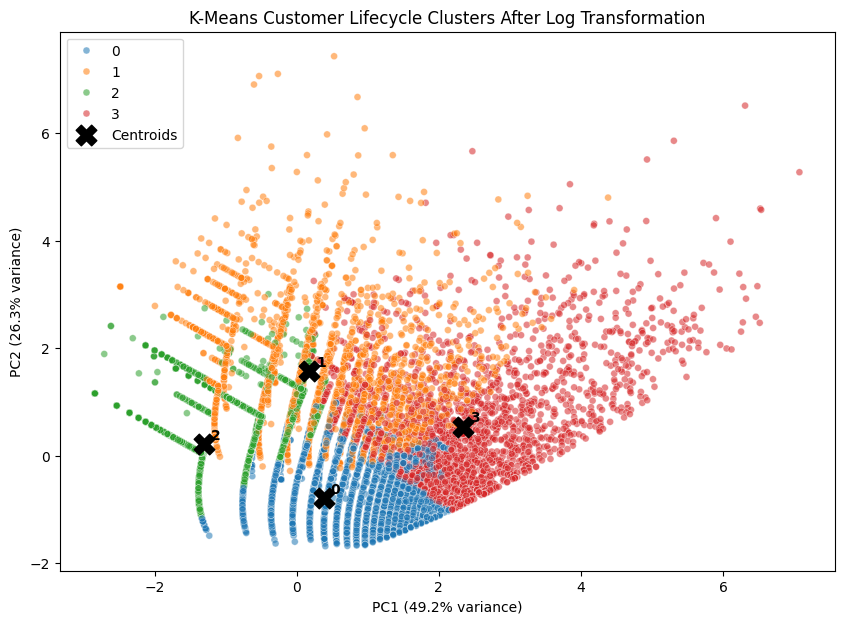

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 3. Fit K-Means on this exact scaled dataset
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
clusters = kmeans.fit_predict(X_scaled2)

# 4. Fit PCA on this exact scaled dataset
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled2)

# Transform the matching K-Means centers using the same PCA object
centers_pca = pca.transform(kmeans.cluster_centers_)

# Create a temporary plotting dataframe to avoid stale PCA columns
plot_df = pd.DataFrame({
    "pca_1": X_pca[:, 0],
    "pca_2": X_pca[:, 1],
    "cluster": clusters
})

# 5. Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_df,
    x="pca_1",
    y="pca_2",
    hue="cluster",
    palette="tab10",
    alpha=0.55,
    s=25
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=220,
    label="Centroids"
)

for i, (x, y) in enumerate(centers_pca):
    plt.text(x + 0.1, y + 0.1, str(i), fontweight="bold")

plt.title("K-Means Customer Lifecycle Clusters After Log Transformation")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend()
plt.show()

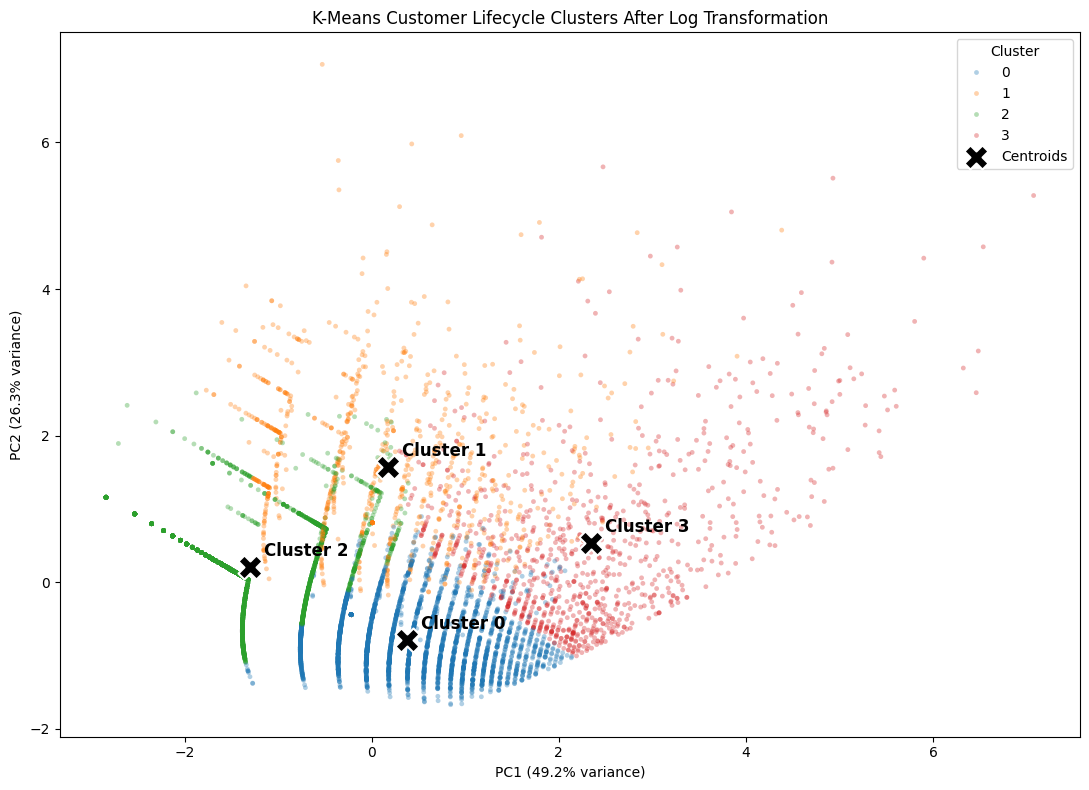

In [ ]:
import numpy as np

# Sample so points don't pile up (plot_df and clusters stay aligned via the same index)
plot_sample = plot_df.sample(n=min(8000, len(plot_df)), random_state=42)

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=plot_sample,
    x="pca_1",
    y="pca_2",
    hue="cluster",
    palette="tab10",
    alpha=0.35,          # lighter so density shows through
    s=12,                # smaller dots
    linewidth=0,         # removes the outline around each dot
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=300,
    edgecolor="white",   # white outline so centroids stand out
    linewidth=1.5,
    zorder=5,            # draw on top of the dots
    label="Centroids"
)

for i, (x, y) in enumerate(centers_pca):
    plt.text(x + 0.15, y + 0.15, f"Cluster {i}", fontweight="bold", fontsize=12, zorder=6)

plt.title("K-Means Customer Lifecycle Clusters After Log Transformation")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend(title="Cluster", loc="upper right")
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=200, bbox_inches="tight")  # crisp image for your write-up
plt.show()

In [ ]:
cluster_profile = feat.groupby("cluster2").agg(
    customers=("Customer ID", "count"),
    frequency_median=("frequency", "median"),
    tenure_days_median=("tenure_days", "median"),
    total_orders_median=("total_orders", "median"),
    cancellation_rate_median=("cancellation_rate", "median")

).round(2)

cluster_profile

,customers,frequency_median,tenure_days_median,total_orders_median,cancellation_rate_median
cluster2,,,,,
0,8530,0.81,203.0,6.0,0.0
1,2430,1.00,98.0,3.0,1.5
2,7534,1.00,25.0,1.0,0.0
3,2625,2.21,322.0,22.0,0.0


In [ ]:
lifecycle_map = {
    0: "Occasional buyer",       # replace based on your profile table
    1: "Declining buyer",
    2: "At-risk buyer",
    3: "Active buyer"
}


feat["lifecycle_state"] = (
    feat["cluster2"].map(lifecycle_map)
)

In [ ]:
feat["lifecycle_state"]

,lifecycle_state
0,Occasional buyer
1,At-risk buyer
2,Occasional buyer
3,Occasional buyer
4,Occasional buyer
...,...
21114,At-risk buyer
21115,Occasional buyer
21116,Declining buyer
21117,Occasional buyer


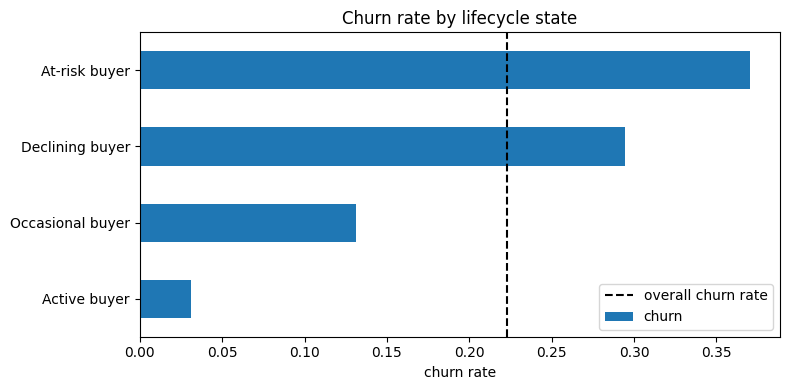

In [ ]:
churn_by_state = feat.groupby("lifecycle_state")["churn"].mean().sort_values()

plt.figure(figsize=(8, 4))
churn_by_state.plot(kind="barh")
plt.axvline(feat["churn"].mean(), color="black", linestyle="--", label="overall churn rate")
plt.xlabel("churn rate")
plt.ylabel("")
plt.title("Churn rate by lifecycle state")
plt.legend()
plt.tight_layout()
plt.show()

## Clustering Customer Lifecycle States: K-means
**Method:** we applied K-means with 4 clusters. to customer-month rows using behavioral features only: [frequency, tenure_days, total_orders, cancellation_rate]. Skewed columns were then log-transformed ([list columns]) and all features were standardized before clustering. (["churn"]) was excluded for analyzing customer behavior only.

| State | What defines it |
|---|---|
| Active buyer | [high total orders, long tenure, highest frequency] |
| Occasional buyer | [moderate orders, moderate tenure, lower frequency] |
| Declining customer | [fewer orders, shorter tenure, lower frquency] |
| At-risk customer | [fewest orders, shortest tenure, lowest frequency] |

**Conclusion:** According to the graph above, we found that within our data, the higher risk the customer had of churn, the higher the rate of churn is for that group.